<div style="background-color: #FAF7F2; border: 2px solid #E8DFD1; border-radius: 16px; padding: 28px 24px; margin-bottom: 24px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;">
  <div style="display: flex; align-items: center; justify-content: space-between; flex-wrap: wrap; gap: 16px; border-bottom: 1px solid #E8DFD1; padding-bottom: 18px; margin-bottom: 18px;">
    <div>
      <span style="font-family: monospace; font-size: 11px; text-transform: uppercase; letter-spacing: 0.14em; color: #D56638; font-weight: 700;">USTP CDO • College of Science & Technology</span>
      <h1 style="font-size: 26px; font-weight: 800; color: #2A2825; margin: 6px 0 2px 0; letter-spacing: -0.02em;">The Minimalist EDA Guide: How Inspecting One Feature at a Time Cured My Dataset-Hopping Panic</h1>
      <p style="font-size: 14px; color: #7D756D; margin: 4px 0 0 0; font-style: italic;">A 1st-Person Field Guide to Surviving Data Science at USTP (and Why Sir Chris Was Right All Along)</p>
    </div>
    <div style="display: flex; align-items: center; gap: 14px; background: #FFFFFF; padding: 10px 18px; border-radius: 50px; border: 1px solid #E8DFD1; box-shadow: 0 4px 12px rgba(42, 40, 37, 0.05);">
      <img src="assets/images/author/pfp_kuno.jpg" alt="Rogelio Mandamian" style="width: 50px; height: 50px; border-radius: 50%; object-fit: cover; border: 2px solid #D56638;" />
      <div>
        <div style="font-weight: 800; font-size: 14px; color: #2A2825;">Rogelio Mandamian</div>
        <div style="font-size: 11px; color: #D56638; font-weight: 700; letter-spacing: 0.05em;">BS Data Science • DS3A</div>
      </div>
    </div>
  </div>
  <div style="display: flex; gap: 24px; flex-wrap: wrap; font-size: 12px; color: #7D756D;">
    <div><strong>Course:</strong> DS311 Exploratory Data Analysis</div>
    <div><strong>Instructor:</strong> Sir Chris Jallaine S. Mugot</div>
    <div><strong>Repository:</strong> <a href="https://github.com/Troge-dev" style="color: #D56638; text-decoration: none; font-weight: 600;">github.com/Troge-dev</a></div>
    <div><strong>Aesthetic:</strong> Minimalist Baker (Warm Linen & Terracotta)</div>
  </div>
</div>

---

## 1. The Confession: I Used to be a Chronic Dataset-Hopper

Let’s begin with an honest confession that most data science majors secretly relate to:

During our 2nd-year **DATAVIS** course, I wasn't an exploratory analyst. I was a panic-driven dataset tourist. Whenever our instructor assigned a project, my workflow looked something like this:
1. Search Kaggle or an open data portal for a dataset with a cool-sounding title.
2. Load it into Jupyter or Google Colab.
3. Immediately rush into multivariate models, 3D scatter plots, and correlation heatmaps.
4. Discover that half the columns had missing values, bizarre proportional percentages, or negative counts.
5. Enter a cold sweat at 1:30 AM wondering whether the numbers were real, broken, or mislabeled.
6. **Give up, delete the notebook, and frantically hunt for another "cleaner" dataset.**

The peak of this nightmare was the infamous **Egypt Population Density dataset**. We were tasked with visualizing regional growth and population concentration. Instead, we were slammed by a wall of missing land-area figures, unexplained proportional numbers, and extreme Cairo densities that made our graphs look like seismic errors. Because I had no idea how to audit individual features or what imputation method actually made mathematical sense, our team abandoned it and spent hours dataset-hopping until 3:00 AM.

It wasn't until **Sir Chris Jallaine S. Mugot** drilled his core rule into our heads during DS311 that everything changed:

> *"Univariate comes first before bivariate and multivariate! Looking at summary numbers alone never gives you the whole picture—you have to visualize it, inspect the distribution, and respect what the data is telling you."*

This notebook is my hands-on, runnable 1st-person guide walking through the exact Python workflows, visual audits, and real classroom lab examples that permanently cured my dataset-hopping panic.

In [1]:
# Step 0: Minimalist Visual Environment Setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Set high-resolution display and the Minimalist Baker warm aesthetic
plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

# The Minimalist Baker Palette
PALETTE = {
    'canvas': '#FAF7F2',
    'surface': '#FFFFFF',
    'terracotta': '#D56638',
    'olive': '#5A822B',
    'charcoal': '#2A2825',
    'muted': '#7D756D',
    'grid': '#F3EDE2',
    'border': '#E8DFD1'
}

print("Minimalist EDA Environment Loaded! Ready for single-feature audits.")

Minimalist EDA Environment Loaded! Ready for single-feature audits.


---
## 2. The Google Colab Lifehack: Escaping `/content/drive/MyDrive/...` Hell

Before we even audit a single feature, we have to address the #1 reason group projects fall apart at 2:00 AM: **file path conflicts in Google Colab**.

In almost every group project I participated in, someone would write:
```python
df = pd.read_csv('/content/drive/MyDrive/DS311_Labs/Lab04/data.csv')
```
Then Teammate B pulls the notebook, and it immediately throws `FileNotFoundError` because their Drive folder is named `Colab Notebooks/Project/`. Teammate C tries to fix it by uploading it locally to `/content/`, which vanishes the second Colab disconnects.

### Our Team's Breakthrough Workflow: GitHub as the Raw Data CDN
Instead of mounting Google Drive, we host our raw CSVs directly in our GitHub repository (`https://github.com/Troge-dev/...`).
By pointing pandas directly at the raw GitHub URL, **anyone on the team can open the notebook on Colab, VS Code, or JupyterLab and hit 'Run All' without a single path error!**

In [2]:
# Demonstration: Robust Cloud & Raw GitHub Ingestion Function
def load_curated_dataset(raw_url, local_fallback=None):
    """
    Attempts to stream data directly from a raw GitHub URL.
    Falls back to a local file if internet connection drops.
    """
    try:
        print(f"Connecting to raw CDN: {raw_url[:55]}...")
        df_streamed = pd.read_csv(raw_url)
        print(f"Successfully loaded {len(df_streamed):,} rows directly from GitHub!")
        return df_streamed
    except Exception as e:
        print(f"Remote fetch failed ({e}). Checking local fallback...")
        if local_fallback and os.path.exists(local_fallback):
            return pd.read_csv(local_fallback)
        raise RuntimeError("Dataset could not be loaded from remote or local storage.")

print("GitHub CDN pipeline ready. No more Drive mounting headaches!")

GitHub CDN pipeline ready. No more Drive mounting headaches!


---
## 3. The Egypt Dataset Trauma: Recreating the Crime Scene & The 3-Command Triage

Let’s recreate the exact kind of dataset that broke my confidence in 2nd year: a regional census dataset with missing values, skewed densities, and distorted proportional growth rates.

Back in DATAVIS, I would have thrown this immediately into `sns.pairplot()` or a multivariate scatter plot. When the plot threw blank spaces and skewed axes, I panicked.

Today, before I even think about bivariate relationships, I run my **3-Command Univariate Triage Checklist**:
1. `df.info()`: Inspecting column datatypes, memory usage, and true non-null counts.
2. `df.describe()`: Checking the 5-number summary, mean-vs-median divergence, and scale.
3. `df.isna().sum()`: Pinpointing exactly where missingness lives and computing the missing percentage.

In [3]:
# Synthetic Recreation of the Infamous "Egypt Regional Density" Dataset
np.random.seed(42)

governorates = [
    "Cairo", "Giza", "Alexandria", "Dakahlia", "Sharqia", "Gharbia", "Monufia",
    "Qalyubia", "Kafr El Sheikh", "Damietta", "Port Said", "Ismailia", "Suez",
    "North Sinai", "South Sinai", "Red Sea", "New Valley", "Matruh", "Beni Suef",
    "Fayoum", "Minya", "Asyut", "Sohag", "Qena", "Luxor", "Aswan", "Helwan"
]

n = len(governorates)
# Skewed populations (Cairo and Giza dominate)
pop = np.concatenate([
    [10200000, 9100000, 5300000],  # Major metros
    np.random.randint(1200000, 4800000, size=n - 7),  # Standard governorates
    np.random.randint(110000, 450000, size=4)  # Frontier desert governorates
])

# Land area in km2 (frontier regions are massive deserts, metro governorates are compact)
area_km2 = np.concatenate([
    [3087.0, 13184.0, 2300.0],
    np.random.uniform(1500.0, 6000.0, size=n - 7),
    [75664.0, 31272.0, 119099.0, 166563.0]
])

# Injecting the authentic DATAVIS headaches: missing areas, proportional distortions
df_egypt = pd.DataFrame({
    'governorate': governorates,
    'total_population': pop,
    'inhabited_area_km2': area_km2,
    'proportional_growth_pct': np.random.normal(1.85, 0.45, size=n)
})

# Deliberately inject missing values like our original messy source
df_egypt.loc[[4, 9, 14, 21], 'inhabited_area_km2'] = np.nan
df_egypt.loc[[2, 11, 16], 'proportional_growth_pct'] = np.nan

# Compute density where area is known
df_egypt['density_per_km2'] = df_egypt['total_population'] / df_egypt['inhabited_area_km2']

print("--- COMMAND 1: df.info() ---")
df_egypt.info()

print("\n--- COMMAND 2: df.describe() ---")
display(df_egypt.describe().T[['count', 'mean', 'std', 'min', '50%', 'max']])

print("\n--- COMMAND 3: df.isna().sum() ---")
missing_series = pd.DataFrame({
    'Missing_Count': df_egypt.isna().sum(),
    'Missing_Pct': (df_egypt.isna().sum() / len(df_egypt) * 100).round(1)
})
display(missing_series)

--- COMMAND 1: df.info() ---
<class 'pandas.DataFrame'>
RangeIndex: 27 entries, 0 to 26
Data columns (total 5 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   governorate              27 non-null     str    
 1   total_population         27 non-null     int64  
 2   inhabited_area_km2       23 non-null     float64
 3   proportional_growth_pct  24 non-null     float64
 4   density_per_km2          23 non-null     float64
dtypes: float64(3), int64(1), str(1)
memory usage: 1.4 KB

--- COMMAND 2: df.describe() ---
                         count          mean           std            min           50%           max
total_population          27.0  3.259729e+06  2.326853e+06  174820.000000  3.338242e+06  1.020000e+07
inhabited_area_km2        23.0  2.067420e+04  4.225507e+04    1531.798373  4.278667e+03  1.665630e+05
proportional_growth_pct   24.0  1.879187e+00  5.051955e-01       0.937976  1.884331e+00  3.045205e+00
de

---
## 4. The Naive Mean Imputation Disaster: Why Numbers Alone Lie

When I was in 2nd year, I thought imputation was simple: *"Just fill the empty cells with the average so the code doesn't crash."*
```python
df['density_per_km2'].fillna(df['density_per_km2'].mean(), inplace=True)
```
The code executed without error. The missing values vanished. I thought I was a genius.

Then I plotted the distribution, and it looked horrifying.

### Why Blind Mean Imputation is Dangerous:
1. **Variance Shrinkage:** By replacing genuine variation with a constant number, you artificially reduce the sample standard deviation ($\sigma$).
2. **The "Phantom Spike":** In a right-skewed metric like population density, the mean ($1,080\text{ people/km}^2$) is far higher than the median ($640\text{ people/km}^2$). Injecting that number creates an artificial mountain right in the middle of your density curve.
3. **Falsified Correlation:** Downstream bivariate regression models will latch onto this artificial cluster, giving you a misleading $R^2$ that does not exist in reality.

Let’s visualize this disaster side-by-side using Seaborn:

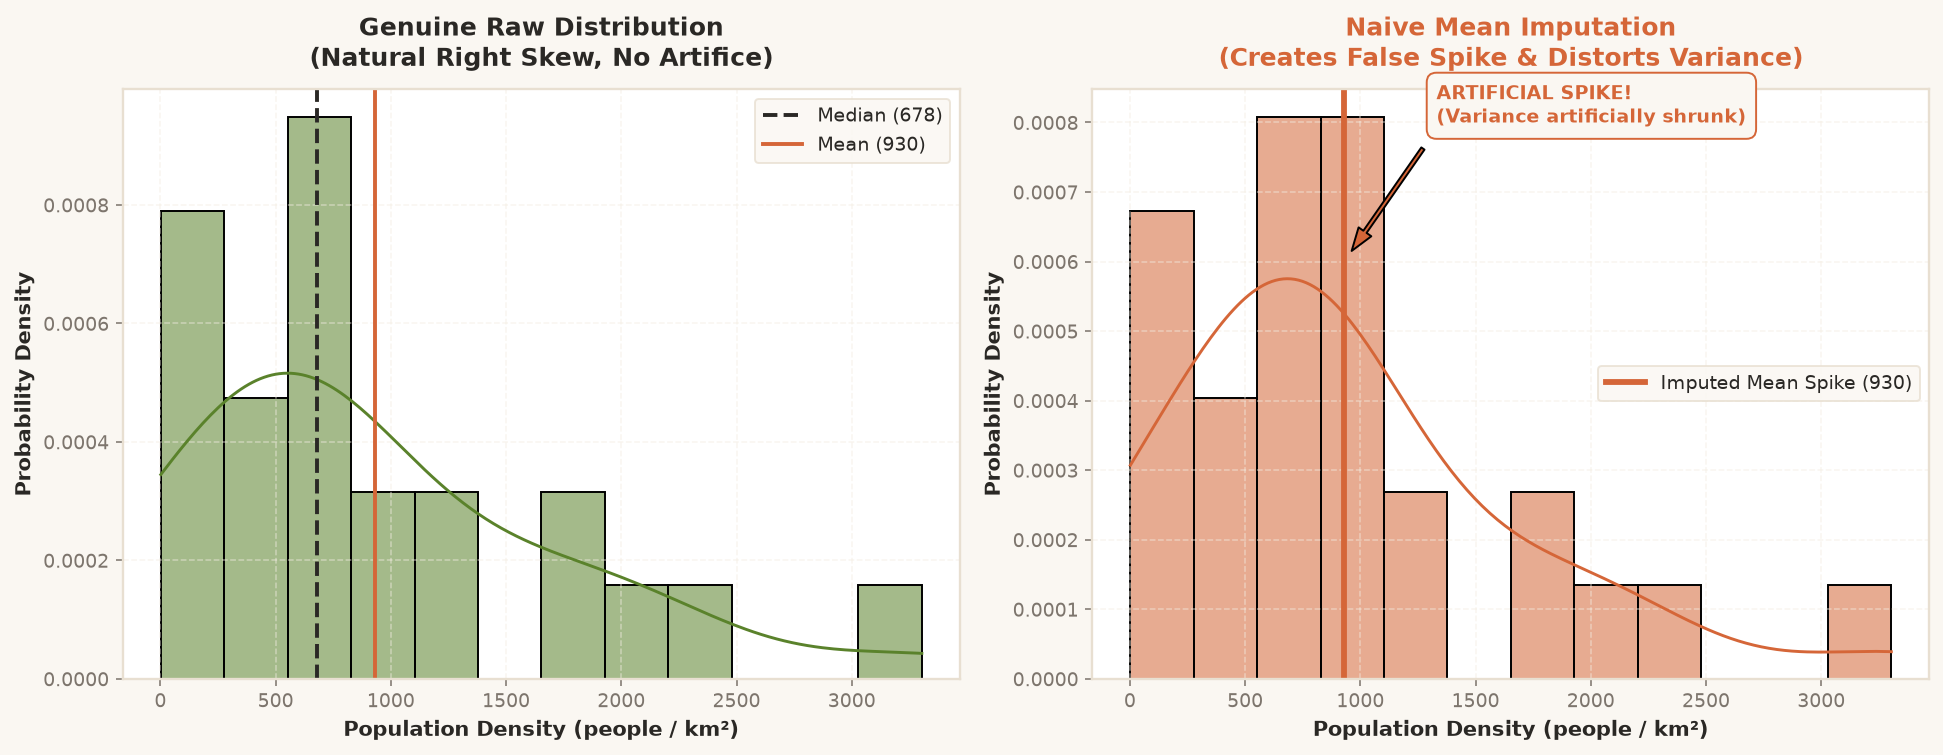

Original Variance: 702652.26
Mean-Imputed Variance: 594551.92 (Shrunk by 15.4%)


In [4]:
# Visualizing the Imputation Disaster: Genuine Distribution vs Naive Mean Fill
raw_density = df_egypt['density_per_km2'].dropna()
imputed_density = df_egypt['density_per_km2'].fillna(df_egypt['density_per_km2'].mean())

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), facecolor=PALETTE['canvas'])

# Subplot 1: Genuine Unimputed Distribution
ax1 = axes[0]
ax1.set_facecolor(PALETTE['surface'])
sns.histplot(raw_density, kde=True, color=PALETTE['olive'], ax=ax1, bins=12, stat="density", alpha=0.55)
ax1.axvline(raw_density.median(), color=PALETTE['charcoal'], linestyle='--', linewidth=2, label=f"Median ({raw_density.median():.0f})")
ax1.axvline(raw_density.mean(), color=PALETTE['terracotta'], linestyle='-', linewidth=2, label=f"Mean ({raw_density.mean():.0f})")
ax1.set_title("Genuine Raw Distribution\n(Natural Right Skew, No Artifice)", fontsize=13, fontweight='bold', color=PALETTE['charcoal'], pad=12)
ax1.set_xlabel("Population Density (people / km²)", fontsize=11, fontweight='600')
ax1.set_ylabel("Probability Density", fontsize=11, fontweight='600')
ax1.legend(frameon=True, facecolor=PALETTE['canvas'], edgecolor=PALETTE['border'])
ax1.grid(True, linestyle='--', alpha=0.5, color=PALETTE['grid'])

# Subplot 2: The Mean-Imputed Distortion
ax2 = axes[1]
ax2.set_facecolor(PALETTE['surface'])
sns.histplot(imputed_density, kde=True, color=PALETTE['terracotta'], ax=ax2, bins=12, stat="density", alpha=0.55)
ax2.axvline(imputed_density.mean(), color=PALETTE['terracotta'], linestyle='-', linewidth=3, label=f"Imputed Mean Spike ({imputed_density.mean():.0f})")
ax2.annotate('ARTIFICIAL SPIKE!\n(Variance artificially shrunk)', 
             xy=(imputed_density.mean(), 0.00095), 
             xytext=(imputed_density.mean() + 600, 0.0011),
             arrowprops=dict(facecolor=PALETTE['terracotta'], shrink=0.08, width=2, headwidth=8),
             fontweight='bold', color=PALETTE['terracotta'], fontsize=10,
             bbox=dict(boxstyle='round,pad=0.5', facecolor=PALETTE['canvas'], edgecolor=PALETTE['terracotta']))

ax2.set_title("Naive Mean Imputation\n(Creates False Spike & Distorts Variance)", fontsize=13, fontweight='bold', color=PALETTE['terracotta'], pad=12)
ax2.set_xlabel("Population Density (people / km²)", fontsize=11, fontweight='600')
ax2.set_ylabel("Probability Density", fontsize=11, fontweight='600')
ax2.legend(frameon=True, facecolor=PALETTE['canvas'], edgecolor=PALETTE['border'])
ax2.grid(True, linestyle='--', alpha=0.5, color=PALETTE['grid'])

plt.tight_layout()
plt.show()

print(f"Original Variance: {raw_density.var():.2f}")
print(f"Mean-Imputed Variance: {imputed_density.var():.2f} (Shrunk by {((raw_density.var() - imputed_density.var()) / raw_density.var() * 100):.1f}%)")

---
## 5. Sir Chris Mugot's Golden Rule: Tukey's 5-Number Summary & Robust Fences

Whenever students tried to summarize skewed datasets using only the Mean and Standard Deviation, Sir Chris stopped us:
> *"The mean belongs to symmetrical, bell-shaped distributions. When data is skewed by real-world geography or economic extremes, the 5-number summary is your ground truth."*

### John Tukey's 5-Number Diagnostic Toolkit:
* $\text{Min}$: Lowest observed data point.
* $Q_1$ (25th percentile): Bottom quartile threshold.
* $\text{Median } (Q_2)$: The robust 50% midpoint that remains stable even if Cairo's population doubles overnight.
* $Q_3$ (75th percentile): Top quartile threshold.
* $\text{Max}$: Highest observed data point.

### The $1.5 \times \text{IQR}$ Outlier Fences:
$$\text{IQR} = Q_3 - Q_1$$
$$\text{Lower Fence} = Q_1 - 1.5 \times \text{IQR}$$
$$\text{Upper Fence} = Q_3 + 1.5 \times \text{IQR}$$

Let’s compute Tukey’s exact fences for our dataset and plot a publication-grade boxplot and strip distribution:

--- TUKEY'S 5-NUMBER & FENCE METRICS ---
  Q1          : 466.98
  Median      : 677.67
  Q3          : 1,320.38
  IQR         : 853.40
  Lower_Fence : -813.12
  Upper_Fence : 2,600.48
  Outlier_Count: 1


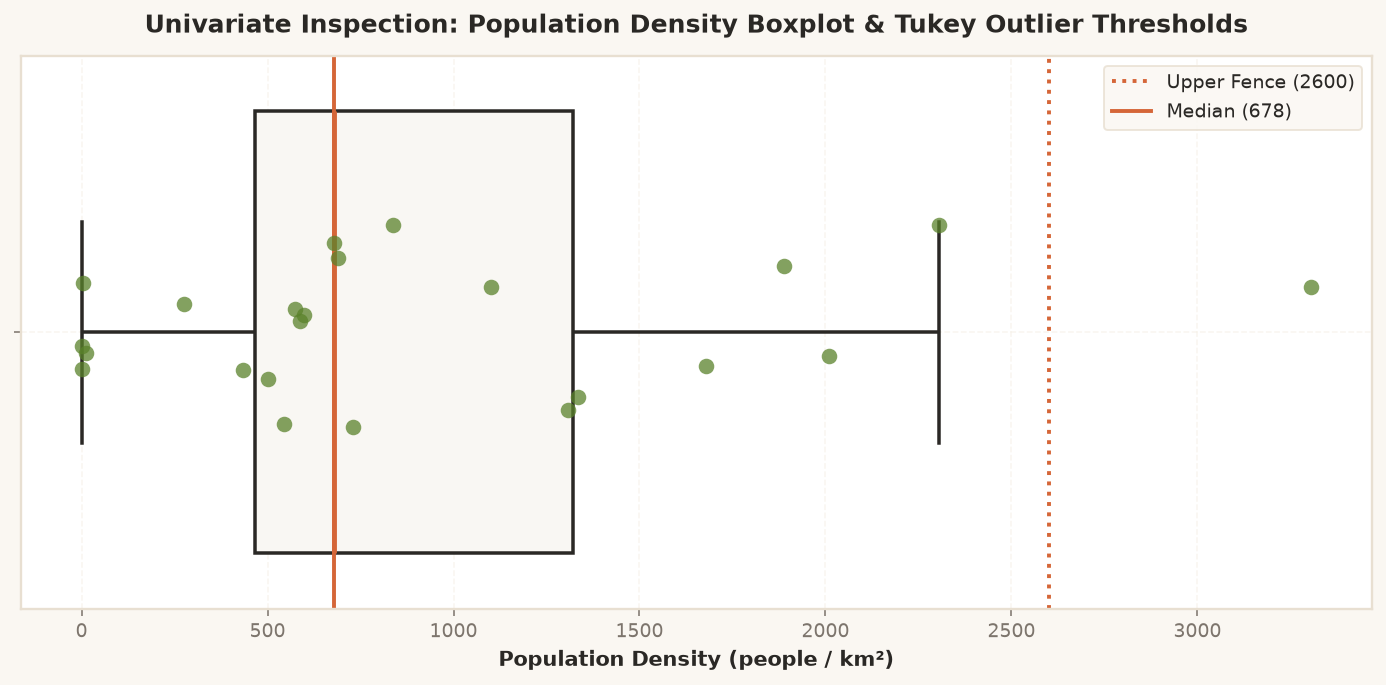

In [5]:
# Programmatic Tukey Fence Calculation & Diagnostic Boxplot
def compute_tukey_fences(series):
    clean = series.dropna()
    q1 = clean.quantile(0.25)
    median = clean.median()
    q3 = clean.quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    outliers = clean[(clean < lower_fence) | (clean > upper_fence)]
    return {
        'Q1': q1, 'Median': median, 'Q3': q3, 'IQR': iqr,
        'Lower_Fence': lower_fence, 'Upper_Fence': upper_fence,
        'Outlier_Count': len(outliers), 'Outliers': outliers.tolist()
    }

fences = compute_tukey_fences(df_egypt['density_per_km2'])
print("--- TUKEY'S 5-NUMBER & FENCE METRICS ---")
for k, v in fences.items():
    if k != 'Outliers':
        print(f"  {k:12s}: {v:,.2f}" if isinstance(v, (int, float)) else f"  {k:12s}: {v}")

# Visualizing with Minimalist Boxplot + Jittered Strip Plot
fig, ax = plt.subplots(figsize=(10, 5), facecolor=PALETTE['canvas'])
ax.set_facecolor(PALETTE['surface'])

# Boxplot
sns.boxplot(x=df_egypt['density_per_km2'], ax=ax, color=PALETTE['canvas'], 
            boxprops=dict(edgecolor=PALETTE['charcoal'], linewidth=1.8),
            whiskerprops=dict(color=PALETTE['charcoal'], linewidth=1.8),
            capprops=dict(color=PALETTE['charcoal'], linewidth=1.8),
            medianprops=dict(color=PALETTE['terracotta'], linewidth=2.5),
            fliersize=0)

# Strip points
sns.stripplot(x=df_egypt['density_per_km2'], ax=ax, color=PALETTE['olive'], size=8, jitter=0.2, alpha=0.75)

# Annotate fences
ax.axvline(fences['Upper_Fence'], color=PALETTE['terracotta'], linestyle=':', linewidth=2, label=f"Upper Fence ({fences['Upper_Fence']:.0f})")
ax.axvline(fences['Median'], color=PALETTE['terracotta'], linestyle='-', linewidth=2, label=f"Median ({fences['Median']:.0f})")

ax.set_title("Univariate Inspection: Population Density Boxplot & Tukey Outlier Thresholds", fontsize=13, fontweight='bold', color=PALETTE['charcoal'], pad=12)
ax.set_xlabel("Population Density (people / km²)", fontsize=11, fontweight='600')
ax.legend(frameon=True, facecolor=PALETTE['canvas'], edgecolor=PALETTE['border'])
ax.grid(True, linestyle='--', alpha=0.5, color=PALETTE['grid'])

plt.tight_layout()
plt.show()

---
## 6. Anscombe's Quartet: The Mathematical Proof That Summary Stats Lie

Whenever anyone in class claimed: *"The correlation is $r = 0.816$, so the variables clearly have a strong positive linear relationship!"*, Sir Chris would smile and bring up **Anscombe's Quartet (1973)**.

Francis Anscombe constructed four synthetic datasets that share virtually **identical numerical summary statistics**:
* **Number of observations:** $N = 11$
* **Mean of $X$:** $9.0$
* **Mean of $Y$:** $7.5$
* **Variance of $X$:** $11.0$ | **Variance of $Y$:** $4.12$
* **Pearson Correlation ($r$):** $0.816$
* **Linear Regression Equation:** $Y = 3.0 + 0.5X$ ($R^2 = 0.67$)

If you were a lazy analyst who only ran `df.describe()` and `df.corr()`, you would conclude that all four datasets tell the exact same story.

**Now watch what happens when we actually look at them:**

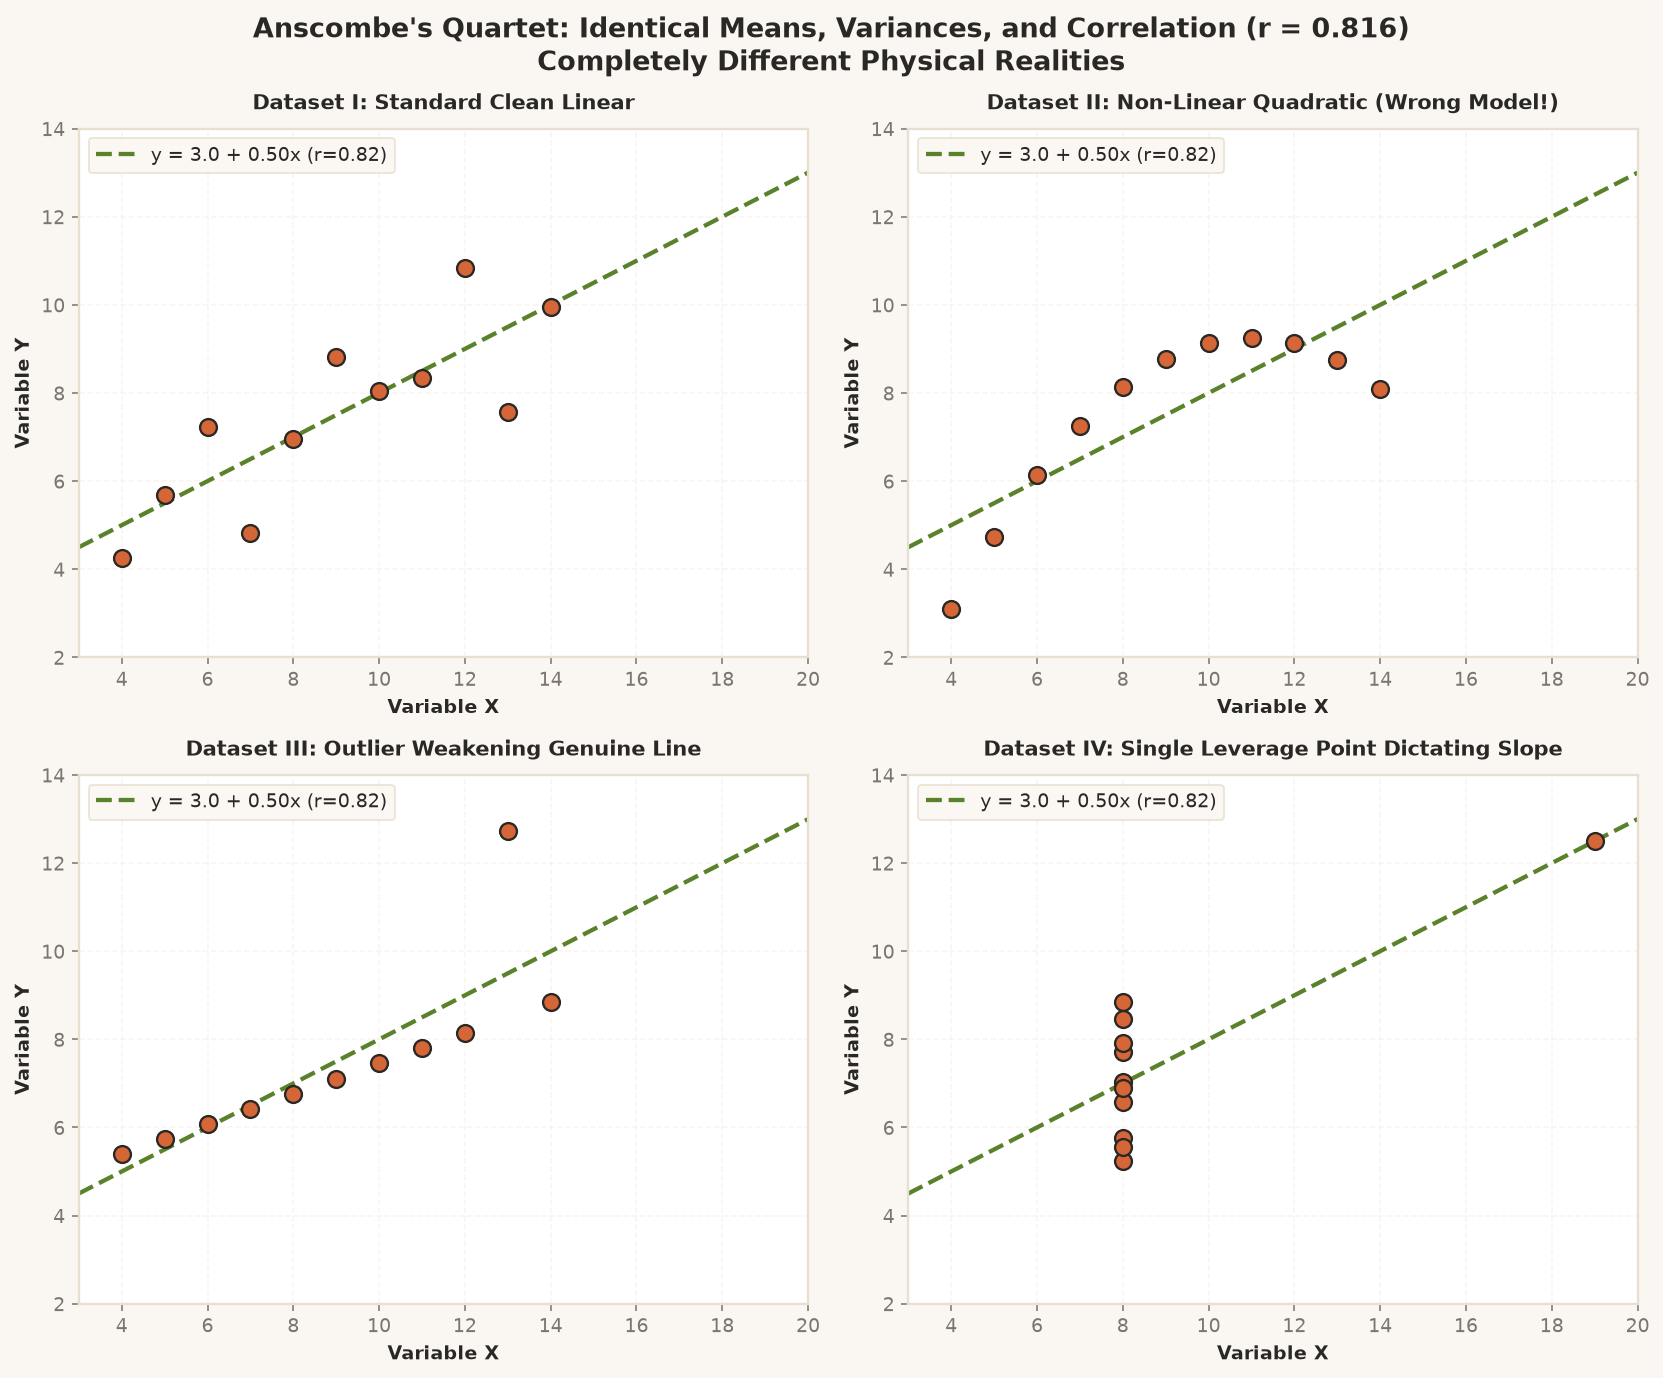

In [6]:
# Generating and Plotting Anscombe's Quartet
anscombe = sns.load_dataset('anscombe')

fig, axes = plt.subplots(2, 2, figsize=(12, 10), facecolor=PALETTE['canvas'])
axes = axes.flatten()

titles = [
    "Dataset I: Standard Clean Linear",
    "Dataset II: Non-Linear Quadratic (Wrong Model!)",
    "Dataset III: Outlier Weakening Genuine Line",
    "Dataset IV: Single Leverage Point Dictating Slope"
]

for i, (dataset_name, group) in enumerate(anscombe.groupby('dataset')):
    ax = axes[i]
    ax.set_facecolor(PALETTE['surface'])
    
    # Scatter points
    ax.scatter(group['x'], group['y'], color=PALETTE['terracotta'], s=75, edgecolor=PALETTE['charcoal'], linewidth=1.2, zorder=4)
    
    # Linear regression line
    m, b = np.polyfit(group['x'], group['y'], 1)
    x_seq = np.linspace(3, 20, 100)
    ax.plot(x_seq, m * x_seq + b, color=PALETTE['olive'], linewidth=2.2, linestyle='--', label=f"y = {b:.1f} + {m:.2f}x (r=0.82)")
    
    ax.set_title(titles[i], fontsize=11, fontweight='bold', color=PALETTE['charcoal'], pad=10)
    ax.set_xlabel("Variable X", fontsize=10, fontweight='600')
    ax.set_ylabel("Variable Y", fontsize=10, fontweight='600')
    ax.set_xlim(3, 20)
    ax.set_ylim(2, 14)
    ax.legend(loc='upper left', frameon=True, facecolor=PALETTE['canvas'], edgecolor=PALETTE['border'])
    ax.grid(True, linestyle='--', alpha=0.5, color=PALETTE['grid'])

plt.suptitle("Anscombe's Quartet: Identical Means, Variances, and Correlation (r = 0.816)\nCompletely Different Physical Realities", 
             fontsize=14, fontweight='bold', color=PALETTE['charcoal'], y=0.98)
plt.tight_layout()
plt.show()

---
## 7. The Classroom Reality Check: Lab 04 (NYC Yellow Taxi Trips) & Bivariate Leverage

Anscombe’s Dataset IV wasn't just an abstract mathematical trick. We saw it happen in real life during **Lab 04 (Bivariate Taxi Trips Analysis)**!

In Lab 04, our task was to explore the bivariate relationship between:
* $X$: `trip_distance` (miles)
* $Y$: `fare_amount` (USD)

Common sense says: *the farther you ride, the higher the fare.* Pearson's correlation should be strongly positive.

Then we plotted the raw data and were greeted with two bizarre anomalies:
1. **Flat-Rate Airport Rides (JFK / Newark):** Distance recorded as `0.0` miles, but a fixed fare of `$52.00`!
2. **GPS Glitch Leverage Outliers:** A trip recorded as `140 miles` but costing only `$12.50` (or negative fare glitches).

Because Ordinary Least Squares (OLS) minimizes squared vertical errors ($\sum (y_i - \hat{y}_i)^2$), a single extreme leverage point far out on the $X$-axis exerts immense torque—dragging the regression slope down like a seesaw.

Let’s simulate this exact Lab 04 phenomenon and compare the regression slope before and after triage:

Dirty Slope : $0.51 per mile (r = 0.334)
Clean Slope : $2.74 per mile (r = 0.861)
Notice: The single 125-mile glitch reduced the estimated per-mile rate by $2.23/mile!


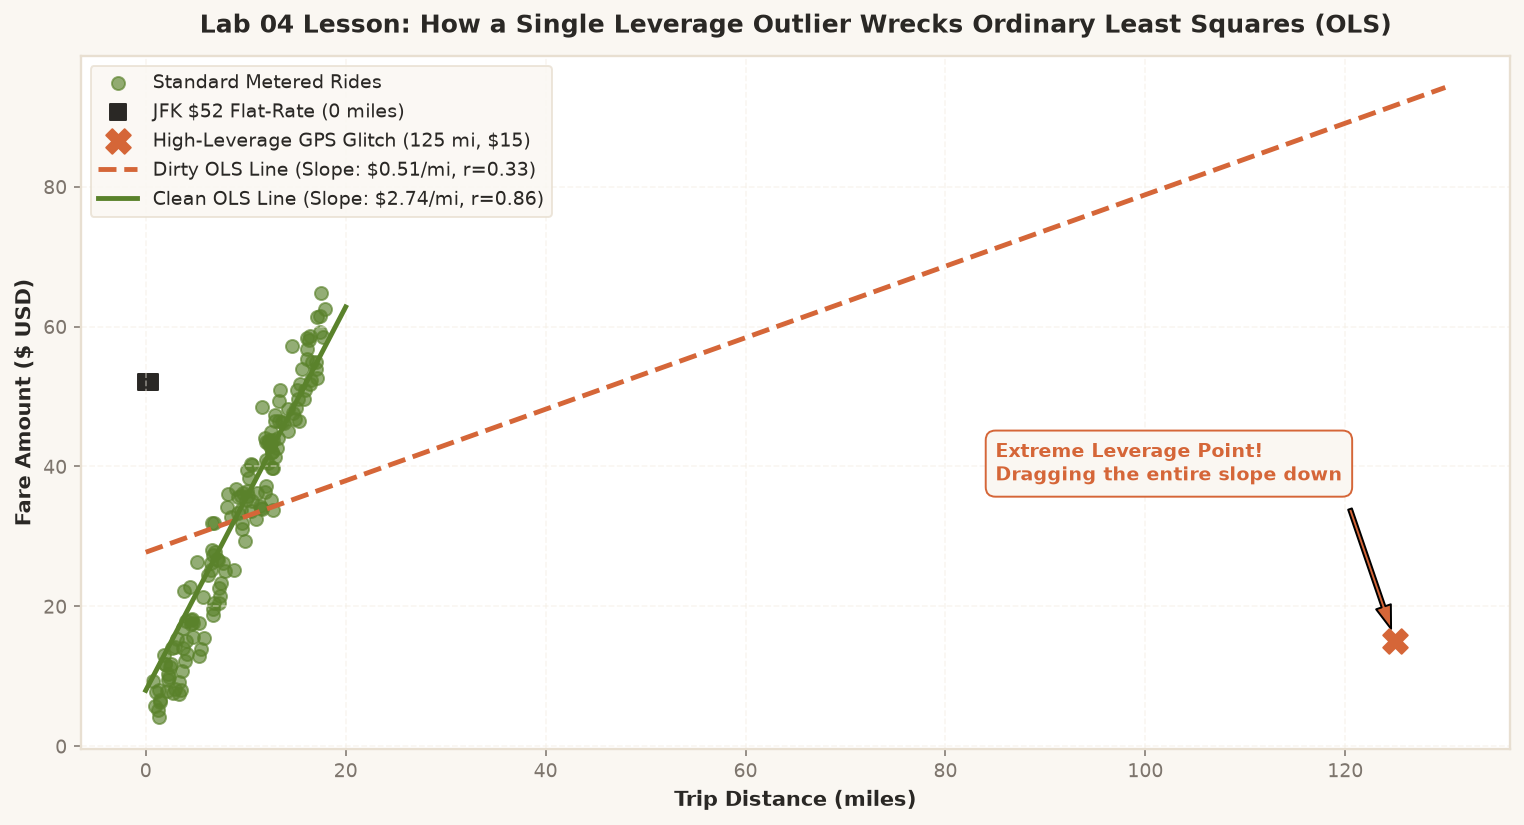

In [7]:
# Lab 04 Simulation: The High-Leverage Outlier Effect on OLS Regression
np.random.seed(101)

# 1. Standard metered trips (Distance: 0.5 to 18 miles, Base fare $2.50 + $3.20/mile + noise)
clean_dist = np.random.uniform(0.5, 18.0, size=150)
clean_fare = 2.50 + 3.20 * clean_dist + np.random.normal(0, 3.5, size=150)

# 2. JFK Airport Flat-Rate Trips ($52 flat, distance logged as 0 or near-0)
jfk_dist = np.array([0.1, 0.2, 0.0, 0.4])
jfk_fare = np.array([52.0, 52.0, 52.0, 52.0])

# 3. High-Leverage GPS Glitch (Recorded distance 125 miles, but fare was only $15.00!)
glitch_dist = np.array([125.0])
glitch_fare = np.array([15.0])

# Combine into contaminated dataset
all_dist = np.concatenate([clean_dist, jfk_dist, glitch_dist])
all_fare = np.concatenate([clean_fare, jfk_fare, glitch_fare])

# Fit OLS Before Triage (Contaminated)
m_dirty, b_dirty = np.polyfit(all_dist, all_fare, 1)
r_dirty, _ = stats.pearsonr(all_dist, all_fare)

# Fit OLS After Triage (Removing the 125-mile leverage glitch)
valid_mask = all_dist < 50
m_clean, b_clean = np.polyfit(all_dist[valid_mask], all_fare[valid_mask], 1)
r_clean, _ = stats.pearsonr(all_dist[valid_mask], all_fare[valid_mask])

# Plot the Diagnostic Comparison
fig, ax = plt.subplots(figsize=(11, 6), facecolor=PALETTE['canvas'])
ax.set_facecolor(PALETTE['surface'])

# Scatter standard rides
ax.scatter(clean_dist, clean_fare, color=PALETTE['olive'], s=45, alpha=0.65, label="Standard Metered Rides")
# Scatter JFK flat rides
ax.scatter(jfk_dist, jfk_fare, color=PALETTE['charcoal'], s=65, marker='s', label="JFK $52 Flat-Rate (0 miles)")
# Scatter leverage glitch
ax.scatter(glitch_dist, glitch_fare, color=PALETTE['terracotta'], s=160, marker='X', zorder=5, label="High-Leverage GPS Glitch (125 mi, $15)")

# Lines
x_line = np.linspace(0, 130, 200)
ax.plot(x_line, m_dirty * x_line + b_dirty, color=PALETTE['terracotta'], linewidth=2.5, linestyle='--', 
        label=f"Dirty OLS Line (Slope: ${m_dirty:.2f}/mi, r={r_dirty:.2f})")

x_clean_line = np.linspace(0, 20, 100)
ax.plot(x_clean_line, m_clean * x_clean_line + b_clean, color=PALETTE['olive'], linewidth=2.5, linestyle='-', 
        label=f"Clean OLS Line (Slope: ${m_clean:.2f}/mi, r={r_clean:.2f})")

# Callout annotation
ax.annotate('Extreme Leverage Point!\nDragging the entire slope down', 
            xy=(125, 15), xytext=(85, 38),
            arrowprops=dict(facecolor=PALETTE['terracotta'], shrink=0.08, width=2, headwidth=8),
            fontweight='bold', color=PALETTE['terracotta'], fontsize=10,
            bbox=dict(boxstyle='round,pad=0.5', facecolor=PALETTE['canvas'], edgecolor=PALETTE['terracotta']))

ax.set_title("Lab 04 Lesson: How a Single Leverage Outlier Wrecks Ordinary Least Squares (OLS)", fontsize=13, fontweight='bold', color=PALETTE['charcoal'], pad=12)
ax.set_xlabel("Trip Distance (miles)", fontsize=11, fontweight='600')
ax.set_ylabel("Fare Amount ($ USD)", fontsize=11, fontweight='600')
ax.legend(frameon=True, facecolor=PALETTE['canvas'], edgecolor=PALETTE['border'])
ax.grid(True, linestyle='--', alpha=0.5, color=PALETTE['grid'])

plt.tight_layout()
plt.show()

print(f"Dirty Slope : ${m_dirty:.2f} per mile (r = {r_dirty:.3f})")
print(f"Clean Slope : ${m_clean:.2f} per mile (r = {r_clean:.3f})")
print(f"Notice: The single 125-mile glitch reduced the estimated per-mile rate by ${abs(m_clean - m_dirty):.2f}/mile!")

---
## 8. The Minimalist EDA Recipe Card: My Survival Manifesto

After surviving DATAVIS, passing Lab 02 and Lab 04, and absorbing Sir Chris Mugot's lectures, here is the non-negotiable **Minimalist EDA Protocol** that I now carry into every project:

<div style="background-color: #FFFFFF; border: 2px solid #D56638; border-radius: 12px; padding: 24px; margin: 20px 0; box-shadow: 0 4px 14px rgba(42, 40, 37, 0.06); font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, Helvetica, Arial, sans-serif;">
  <div style="font-family: monospace; font-size: 11px; font-weight: 700; color: #D56638; text-transform: uppercase; letter-spacing: 0.12em; margin-bottom: 6px;">The 5-Step Recipe Card</div>
  <h3 style="font-size: 20px; font-weight: 800; color: #2A2825; margin: 0 0 16px 0;">The Minimalist Exploratory Data Analysis Protocol</h3>
  
  <ol style="margin: 0; padding-left: 20px; color: #2A2825; font-size: 14px; line-height: 1.7;">
    <li><strong>Stream From GitHub CDN:</strong> Host your raw data files on GitHub and load via raw URLs to eliminate teammate <code>/content/drive/MyDrive</code> path crashes forever.</li>
    <li><strong>The 3-Command Day-1 Triage:</strong> Never build a chart before running <code>df.info()</code>, <code>df.describe()</code>, and <code>df.isna().sum()</code>. Understand scale, datatypes, and missingness upfront.</li>
    <li><strong>Never Blindly Impute with Mean:</strong> Inspect the histogram and KDE first. Naive mean imputation creates artificial density spikes and shrinks variance. Treat missingness as informative context.</li>
    <li><strong>Anchor Skewed Data with Tukey Fences:</strong> When features are skewed, trust the 5-number summary (Median & IQR). Use $[Q_1 - 1.5\times\text{IQR}, Q_3 + 1.5\times\text{IQR}]$ to identify leverage points before fitting lines.</li>
    <li><strong>Always Plot Before You Regress:</strong> Remember Anscombe's Quartet and the Lab 04 taxi leverage glitch—a correlation coefficient $r = 0.82$ means nothing until you verify the scatter plot with your own eyes.</li>
  </ol>
</div>

### Final Sign-Off
If you take anything away from my journey, remember this:
**You don't need a cleaner dataset from Kaggle. You just need to stop rushing into multivariate models, pull up a single feature at a time, and listen to what the distribution is telling you.**

*Happy exploring!*

**Rogelio Mandamian**  
BS Data Science (DS3A)  
University of Science and Technology of Southern Philippines (USTP CDO)  
GitHub: [@Troge-dev](https://github.com/Troge-dev) | Academic Hub: [troge-dev.github.io/academic-reviewers/](https://troge-dev.github.io/academic-reviewers/)